# 1. Problem Statement

## 1.1 The Challenge

The task of this competition is to **predict whether a customer will continue with their bank account or close it (churn)**.

This is a **binary classification problem**, where the target variable indicates whether a customer has exited the bank:

- `1` → Customer has churned
- `0` → Customer has remained with the bank

The goal is to build a machine learning model that can accurately identify customers who are likely to churn based on their demographic, financial, and banking behavior.

## 1.2 About the Dataset

The **Bank Customer Churn Dataset** is a commonly used dataset for predicting customer churn in the banking industry. It contains information about bank customers who either **left the bank or remained customers**.

The dataset includes the following attributes:

| Feature | Description |
|---|---|
| **Customer ID** | A unique identifier for each customer |
| **Surname** | The customer's surname or last name |
| **Credit Score** | A numerical value representing the customer's credit score |
| **Geography** | The country where the customer resides (France, Spain, or Germany) |
| **Gender** | The customer's gender (Male or Female) |
| **Age** | The customer's age |
| **Tenure** | The number of years the customer has been with the bank |
| **Balance** | The customer's account balance |
| **NumOfProducts** | The number of banking products used by the customer, such as savings accounts or credit cards |
| **HasCrCard** | Indicates whether the customer has a credit card (`1` = Yes, `0` = No) |
| **IsActiveMember** | Indicates whether the customer is an active bank member (`1` = Yes, `0` = No) |
| **EstimatedSalary** | The customer's estimated salary |
| **Exited** | The target variable indicating whether the customer has churned (`1` = Yes, `0` = No) |

### Target Variable

The target variable for this competition is **`Exited`**.

- `0` → Customer stayed with the bank
- `1` → Customer exited/churned

The objective is therefore to develop a machine learning model that can learn patterns from the available customer information and **predict the probability of customer churn**.

<!--
![Stimulator Diagram 1](docs/stimulator1.png)
![Stimulator Diagram 2](docs/stimulator2.png)
![Stimulator Diagram 3](docs/stimulator3.png)
-->

---

<div align="center">

# ChurnAI

### Bank customer churn: from model research to a live retention dashboard

Predict which customers are likely to leave, understand why, and see which actions lower the risk the most.

![Python](https://img.shields.io/badge/Python-3.9%2B-3776AB?logo=python&logoColor=white)
![Flask](https://img.shields.io/badge/Flask-API%20%2B%20UI-000000?logo=flask&logoColor=white)
![scikit-learn](https://img.shields.io/badge/scikit--learn-model-F7931E?logo=scikitlearn&logoColor=white)
![Models](https://img.shields.io/badge/compared-RF%20%7C%20XGBoost%20%7C%20LightGBM%20%7C%20CatBoost-123c73)
![AUC](https://img.shields.io/badge/hold--out%20AUC-0.89-1f8a70)
![Status](https://img.shields.io/badge/status-active-1f8a70)

[Overview](#overview) · [Quick start](#quick-start) · [Research notebook](#part-1-research-notebook) · [Dashboard](#part-2-the-dashboard) · [API](#api-reference) · [Deployment](#deployment) · [Limitations](#limitations-and-responsible-use)

</div>


![Stimulator Diagram 1](docs/stimulator1.png)
![Stimulator Diagram 2](docs/stimulator2.png)
![Stimulator Diagram 3](docs/stimulator3.png)

---


# 2. Loading Packages

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import os
from sklearn import set_config
from sklearn.pipeline import Pipeline, make_pipeline, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, StandardScaler

from sklearn.ensemble import RandomForestClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

from sklearn.model_selection import GridSearchCV, train_test_split


from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
import warnings
warnings.filterwarnings("ignore")

In [108]:
df = pd.read_csv("/Users/abidemiavoseh/Bank-Customer-Churn-Prediction-using-Machine-Learning/data/train.csv")
df.head()

,id,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,0,15674932,Okwudilichukwu,668,France,Male,33.0,3,0.00,2,1.0,0.0,181449.97,0
1,1,15749177,Okwudiliolisa,627,France,Male,33.0,1,0.00,2,1.0,1.0,49503.50,0
2,2,15694510,Hsueh,678,France,Male,40.0,10,0.00,2,1.0,0.0,184866.69,0
3,3,15741417,Kao,581,France,Male,34.0,2,148882.54,1,1.0,1.0,84560.88,0
4,4,15766172,Chiemenam,716,Spain,Male,33.0,5,0.00,2,1.0,1.0,15068.83,0


In [109]:
df.head()

,id,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,0,15674932,Okwudilichukwu,668,France,Male,33.0,3,0.00,2,1.0,0.0,181449.97,0
1,1,15749177,Okwudiliolisa,627,France,Male,33.0,1,0.00,2,1.0,1.0,49503.50,0
2,2,15694510,Hsueh,678,France,Male,40.0,10,0.00,2,1.0,0.0,184866.69,0
3,3,15741417,Kao,581,France,Male,34.0,2,148882.54,1,1.0,1.0,84560.88,0
4,4,15766172,Chiemenam,716,Spain,Male,33.0,5,0.00,2,1.0,1.0,15068.83,0


In [110]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 165034 entries, 0 to 165033
Data columns (total 14 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   id               165034 non-null  int64  
 1   CustomerId       165034 non-null  int64  
 2   Surname          165034 non-null  str    
 3   CreditScore      165034 non-null  int64  
 4   Geography        165034 non-null  str    
 5   Gender           165034 non-null  str    
 6   Age              165034 non-null  float64
 7   Tenure           165034 non-null  int64  
 8   Balance          165034 non-null  float64
 9   NumOfProducts    165034 non-null  int64  
 10  HasCrCard        165034 non-null  float64
 11  IsActiveMember   165034 non-null  float64
 12  EstimatedSalary  165034 non-null  float64
 13  Exited           165034 non-null  int64  
dtypes: float64(5), int64(6), str(3)
memory usage: 20.4 MB


In [111]:
df.isnull().sum()

id                 0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [112]:
df.duplicated()

0         False
1         False
2         False
3         False
4         False
          ...  
165029    False
165030    False
165031    False
165032    False
165033    False
Length: 165034, dtype: bool

In [113]:
df.duplicated().sum()

0

In [114]:
df.describe()

,id,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,165034.0000,1.650340e+05,165034.000000,165034.000000,165034.000000,165034.000000,165034.000000,165034.000000,165034.000000,165034.000000,165034.000000
mean,82516.5000,1.569201e+07,656.454373,38.125888,5.020353,55478.086689,1.554455,0.753954,0.497770,112574.822734,0.211599
std,47641.3565,7.139782e+04,80.103340,8.867205,2.806159,62817.663278,0.547154,0.430707,0.499997,50292.865585,0.408443
min,0.0000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.000000,0.000000,11.580000,0.000000
25%,41258.2500,1.563314e+07,597.000000,32.000000,3.000000,0.000000,1.000000,1.000000,0.000000,74637.570000,0.000000
50%,82516.5000,1.569017e+07,659.000000,37.000000,5.000000,0.000000,2.000000,1.000000,0.000000,117948.000000,0.000000
75%,123774.7500,1.575682e+07,710.000000,42.000000,7.000000,119939.517500,2.000000,1.000000,1.000000,155152.467500,0.000000
max,165033.0000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.000000,1.000000,199992.480000,1.000000


In [115]:
df.columns

Index(['id', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender',
       'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Exited'],
      dtype='str')

In [116]:
df.rename(columns={"RowNumber": "id"}, inplace=True)

In [117]:
df.shape

(165034, 14)

In [118]:
df.size

2310476

In [119]:
df["IsActiveMember"].unique()

array([0., 1.])

In [120]:
df["IsActiveMember"].value_counts()

IsActiveMember
0.0    82885
1.0    82149
Name: count, dtype: int64

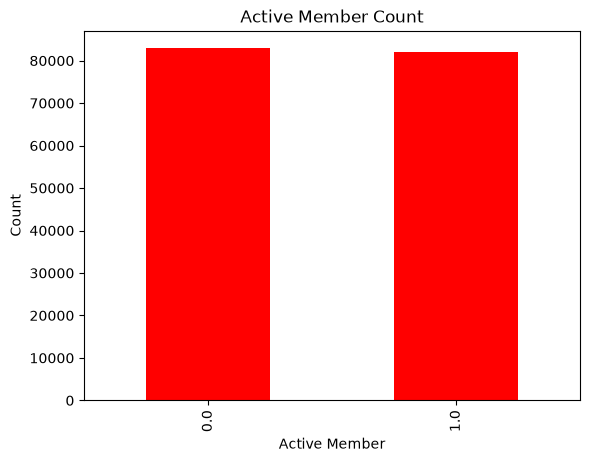

In [121]:
df["IsActiveMember"].value_counts().plot(kind="bar",  xlabel="Active Member", ylabel="Count", color="red", title="Active Member Count")
plt.show()

In [122]:
df["IsActiveMember"] = df["IsActiveMember"].astype(float)
df["IsActiveMember"]

0         0.0
1         1.0
2         0.0
3         1.0
4         1.0
         ... 
165029    1.0
165030    0.0
165031    1.0
165032    1.0
165033    0.0
Name: IsActiveMember, Length: 165034, dtype: float64

In [123]:
df["CustomerId"].head()

0    15674932
1    15749177
2    15694510
3    15741417
4    15766172
Name: CustomerId, dtype: int64

In [124]:
df.duplicated().sum()

0

In [125]:
df["CustomerId"].duplicated().sum()

141813

In [126]:
df.drop(columns=["CustomerId"], inplace=True)

In [127]:
df.head()

,id,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,0,Okwudilichukwu,668,France,Male,33.0,3,0.00,2,1.0,0.0,181449.97,0
1,1,Okwudiliolisa,627,France,Male,33.0,1,0.00,2,1.0,1.0,49503.50,0
2,2,Hsueh,678,France,Male,40.0,10,0.00,2,1.0,0.0,184866.69,0
3,3,Kao,581,France,Male,34.0,2,148882.54,1,1.0,1.0,84560.88,0
4,4,Chiemenam,716,Spain,Male,33.0,5,0.00,2,1.0,1.0,15068.83,0


In [128]:
df["Exited"].value_counts(normalize=True)

Exited
0    0.788401
1    0.211599
Name: proportion, dtype: float64

<Axes: >

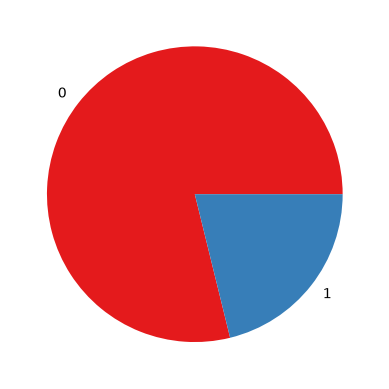

In [129]:
df["Exited"].value_counts().plot(kind="pie")

# 3. Univariate Analysis 

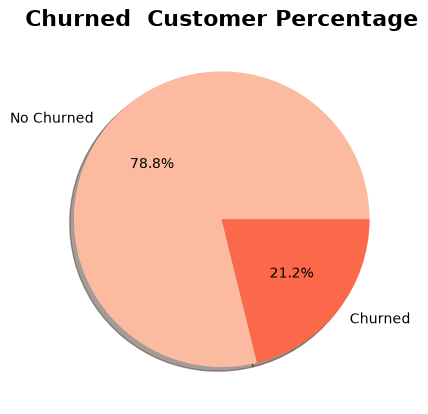

In [130]:
sns.set_palette("Reds", 3)
plt.pie(df["Exited"].value_counts(), labels=["No Churned","Churned"], shadow=True, autopct="%1.1f%%")
plt.title("Churned  Customer Percentage", fontsize=16, fontweight="bold")
plt.show()

* Only 20.4% has insignificantly churned the company without an any imperative reason

In [131]:
df["Surname"].head(10)

0    Okwudilichukwu
1     Okwudiliolisa
2             Hsueh
3               Kao
4         Chiemenam
5          Genovese
6            Ch'ang
7       Chukwuebuka
8             Manna
9          Cattaneo
Name: Surname, dtype: str

In [132]:
df["Surname"].value_counts()

Surname
Hsia         2456
T'ien        2282
Hs?          1611
Kao          1577
Maclean      1577
             ... 
Christmas       1
Ah Mouy         1
Aliyev          1
McMinn          1
Elkins          1
Name: count, Length: 2797, dtype: int64

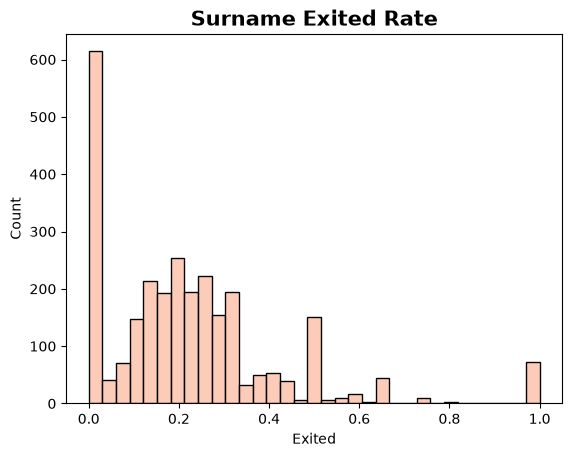

In [133]:
sns.histplot(df.groupby("Surname")["Exited"].mean().sort_values(ascending=True))
plt.title("Surname Exited Rate", fontsize=15, fontweight="bold")
plt.show()

In [134]:
df[df['Surname']=='Brown'].sample(5)

,id,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
149197,149197,Brown,840,France,Female,32.0,7,0.00,2,1.0,1.0,90908.95,0
161381,161381,Brown,684,Germany,Male,36.0,4,78939.32,1,0.0,1.0,165008.97,0
135086,135086,Brown,703,Spain,Female,36.0,8,100116.82,1,1.0,1.0,162503.48,0
12557,12557,Brown,739,France,Male,33.0,2,121063.85,1,1.0,0.0,85578.63,0
7099,7099,Brown,817,France,Female,35.0,7,81070.34,2,0.0,0.0,80985.88,0


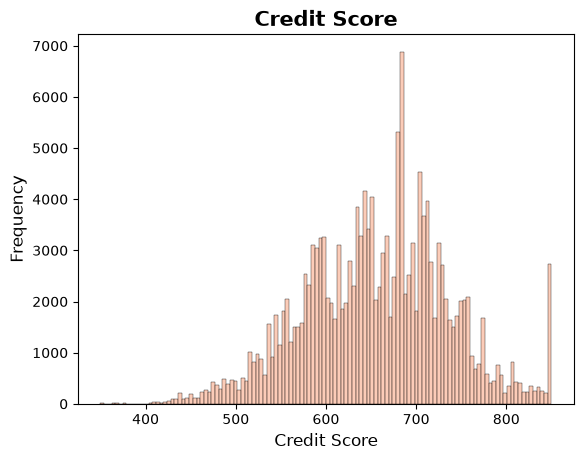

In [135]:
sns.histplot(df["CreditScore"])
plt.title("Credit Score", fontsize=15, fontweight="bold")
plt.xlabel("Credit Score", fontsize=12)
plt.ylabel("Frequency", fontsize=12)    
plt.show()

In [136]:
df["Geography"].value_counts()

Geography
France     94215
Spain      36213
Germany    34606
Name: count, dtype: int64

<Axes: title={'center': 'Geography Count'}, xlabel='Geography', ylabel='Count'>

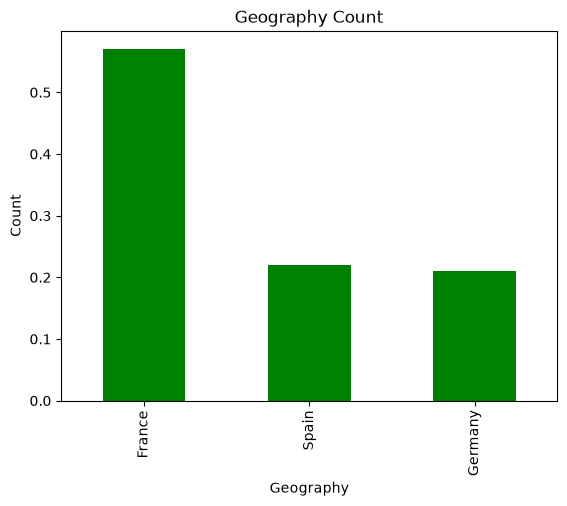

In [137]:
df["Geography"].value_counts(normalize=True).plot(kind="bar", xlabel="Geography", ylabel="Count", color="green", title="Geography Count")

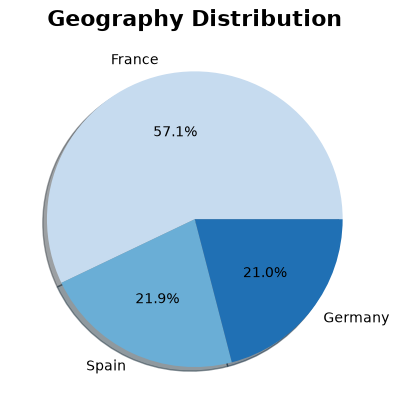

In [138]:
sns.set_palette("Blues", 3)
plt.pie(df["Geography"].value_counts(), labels=df["Geography"].value_counts().index, shadow=True, autopct="%1.1f%%")
plt.title("Geography Distribution", fontsize=16, fontweight="bold")
plt.show()

In [139]:
df["Geography"].head(5)

0    France
1    France
2    France
3    France
4     Spain
Name: Geography, dtype: str

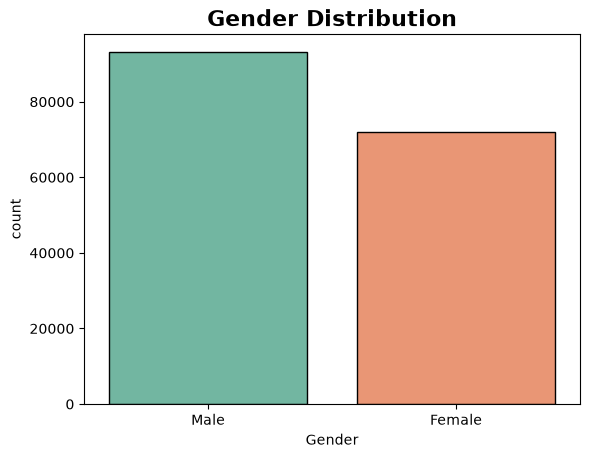

In [140]:
sns.countplot(data=df,x="Gender", edgecolor="black", palette="Set2")
plt.title("Gender Distribution", fontsize=16, fontweight="bold")
plt.show()

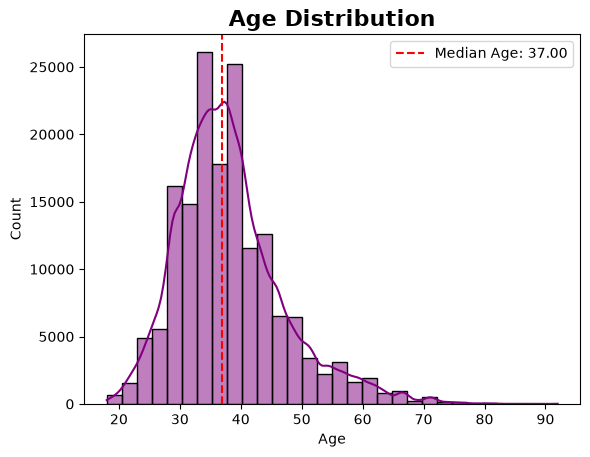

In [141]:
sns.histplot(data=df, x="Age", bins=30, kde=True, color="purple")
plt.axvline(x=df["Age"].median(), color="red", linestyle="--", label=f"Median Age: {df['Age'].median():.2f}")
plt.title("Age Distribution", fontsize=16, fontweight="bold")   
plt.legend()
plt.show()

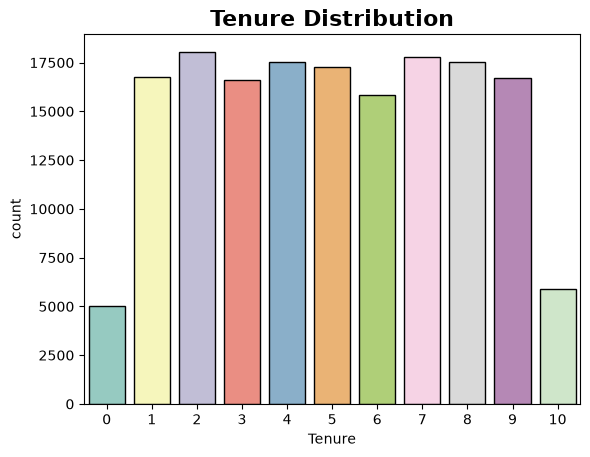

In [142]:
sns.countplot(data=df, x="Tenure", palette="Set3", edgecolor="black", color="#FF5733")
plt.title("Tenure Distribution", fontsize=16, fontweight="bold")
plt.show()

In [143]:
df["Balance"].value_counts()

Balance
0.00         89648
124577.33       88
127864.40       64
122314.50       63
129855.32       59
             ...  
140791.57        1
118022.74        1
117412.34        1
134937.10        1
110993.29        1
Name: count, Length: 30075, dtype: int64

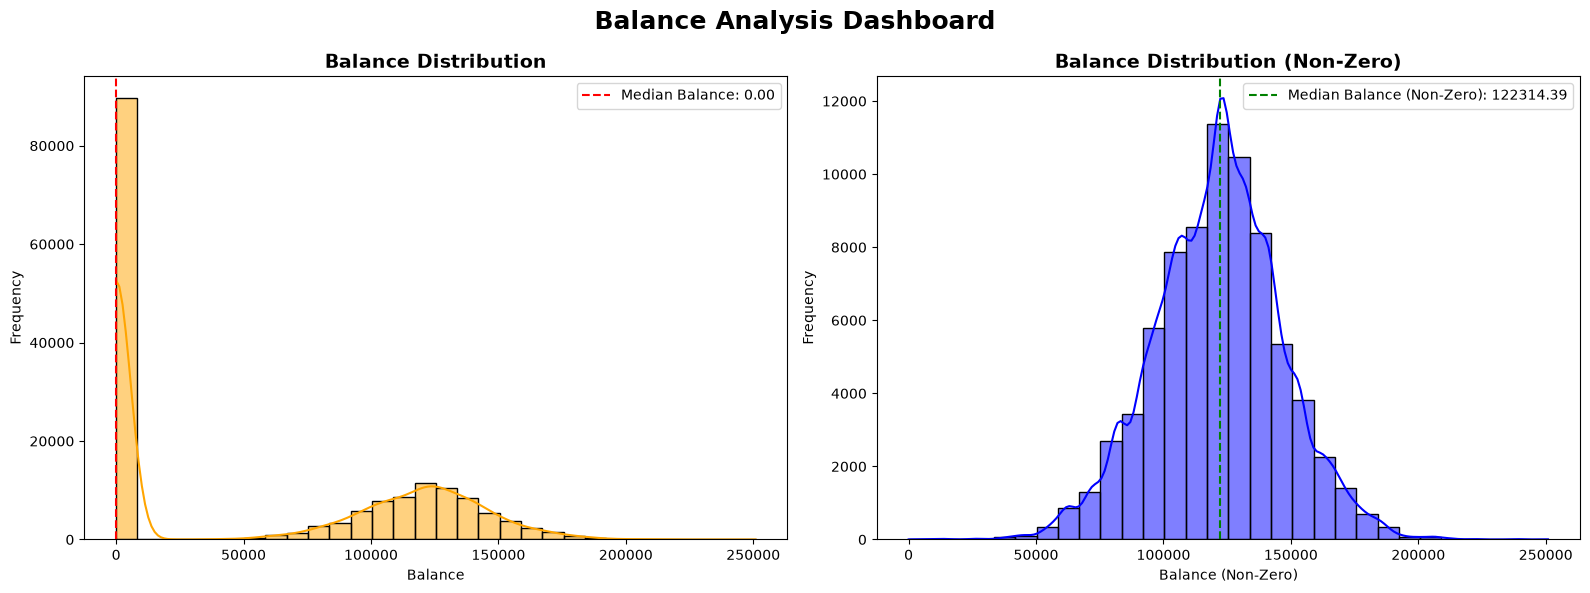

In [144]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))  # Increased width slightly for side-by-side

# Plot 1: Full distribution (including zeros) on ax[0]
sns.histplot(data=df, x="Balance", bins=30, kde=True, color="orange", ax=ax[0])
ax[0].axvline(df["Balance"].median(), color="red", linestyle="--", label=f"Median Balance: {df['Balance'].median():.2f}")
ax[0].set_title("Balance Distribution", fontsize=14, fontweight="bold")
ax[0].set_xlabel("Balance")
ax[0].set_ylabel("Frequency")
ax[0].legend()

# Plot 2: Non-zero distribution on ax[1]
sns.histplot(data=df[df["Balance"]!=0], x="Balance", bins=30, kde=True, color="blue", ax=ax[1])
kk = df[df["Balance"]!=0]["Balance"].median()
ax[1].axvline(x=kk, color="green", linestyle="--", label=f"Median Balance (Non-Zero): {kk:.2f}")
ax[1].set_title("Balance Distribution (Non-Zero)", fontsize=14, fontweight="bold")
ax[1].set_xlabel("Balance (Non-Zero)")
ax[1].set_ylabel("Frequency")
ax[1].legend()

# Overall Figure title
fig.suptitle("Balance Analysis Dashboard", fontsize=18, fontweight="bold")

# Adjust spacing so titles and labels don't overlap
plt.tight_layout()
plt.show()

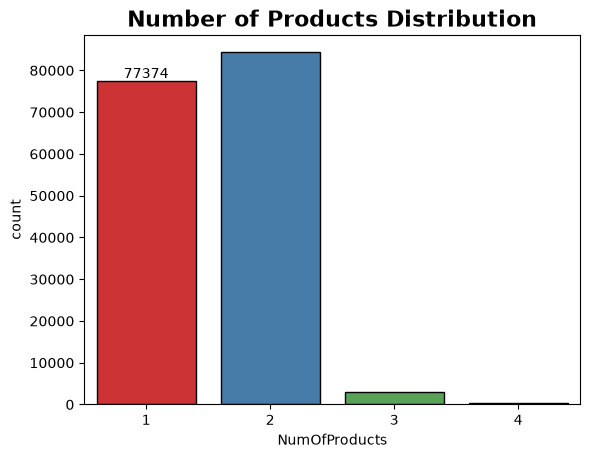

In [145]:
g = sns.countplot(data=df, x="NumOfProducts", palette="Set1", edgecolor="black")
g.bar_label(g.containers[0])
plt.title("Number of Products Distribution", fontsize=16, fontweight="bold")
plt.show()

## Understanding the Importance of Number of Products in Churn Prediction
Understanding the number of products a customer holds with the bank can be a crucial predictor for churn prediction models. Here's why:

* Engagement: Generally, the more products a customer has with a bank, the more engaged they are with that bank. Engaged customers are less likely to churn because they have invested more in the bank's ecosystem.

* Customer Lifetime Value (CLV): Customers with multiple products tend to have higher CLV. They generate more revenue for the bank over their lifetime compared to customers with only one product.

* Cross-Selling Opportunities: The number of products a customer has can also indicate potential opportunities for cross-selling or upselling additional products. Understanding this can inform targeted marketing strategies aimed at increasing the number of products per customer.

* Risk Management: Customers with a diverse portfolio of products may be less likely to churn because they have deeper relationships with the bank. Conversely, customers with only one product may be at higher risk of churn if they find a better offer elsewhere.

* Data Quality: In some cases, the number of products a customer has can also serve as a proxy for data quality. For instance, if a customer has an unusually high or low number of products compared to similar customers, it could indicate errors in the data that need to be investigate

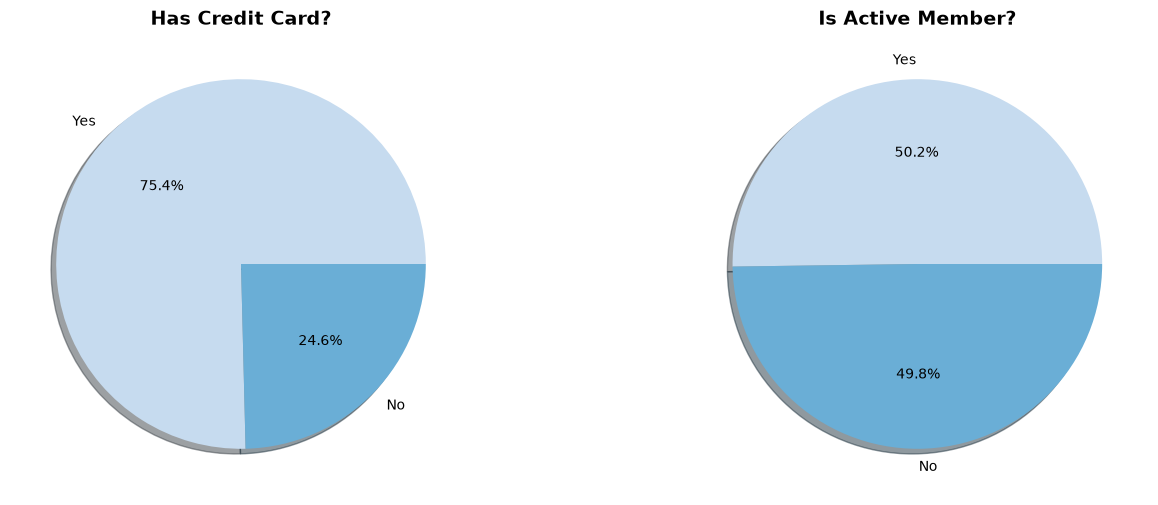

In [146]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))  # Increased width slightly for side-by-side
sns.set_palette("Set2", 3)
# Plot 1: Full distribution (including zeros) on ax[0]
ax[0].pie(df["HasCrCard"].value_counts(), labels=["Yes", "No"], shadow=True, autopct="%1.1f%%")
ax[0].set_title("Has Credit Card?", fontsize=14, fontweight="bold") 


ax[1].pie(df["IsActiveMember"].value_counts(), labels=["Yes", "No"], shadow=True, autopct="%1.1f%%")
ax[1].set_title("Is Active Member?", fontsize=14, fontweight="bold") 
plt.show()
fig.suptitle("Credit Card and Active Member Analysis", fontsize=18, fontweight="bold")
fig.tight_layout()  # Adjust layout to prevent overlap
plt.show()

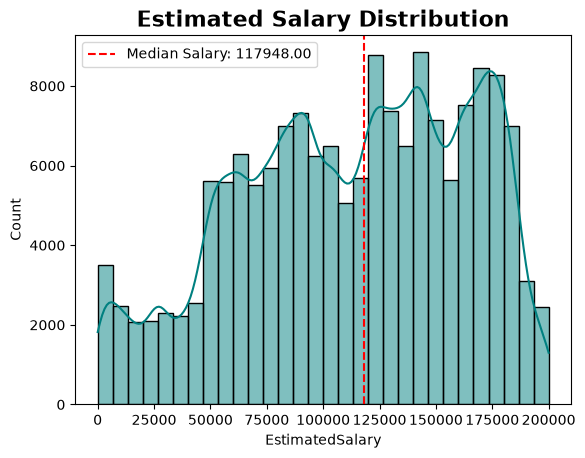

In [147]:
sns.histplot(data=df, x="EstimatedSalary", bins=30, kde=True, color="teal")
plt.axvline(x=df["EstimatedSalary"].median(), color="red", linestyle="--", label=f"Median Salary: {df['EstimatedSalary'].median():.2f}")
plt.title("Estimated Salary Distribution", fontsize=16, fontweight="bold")   
plt.legend()
plt.show()

# 4- Bivariate Analysis

In [148]:
df.groupby("Geography")["Exited"].mean()

Geography
France     0.165282
Germany    0.378952
Spain      0.172176
Name: Exited, dtype: float64

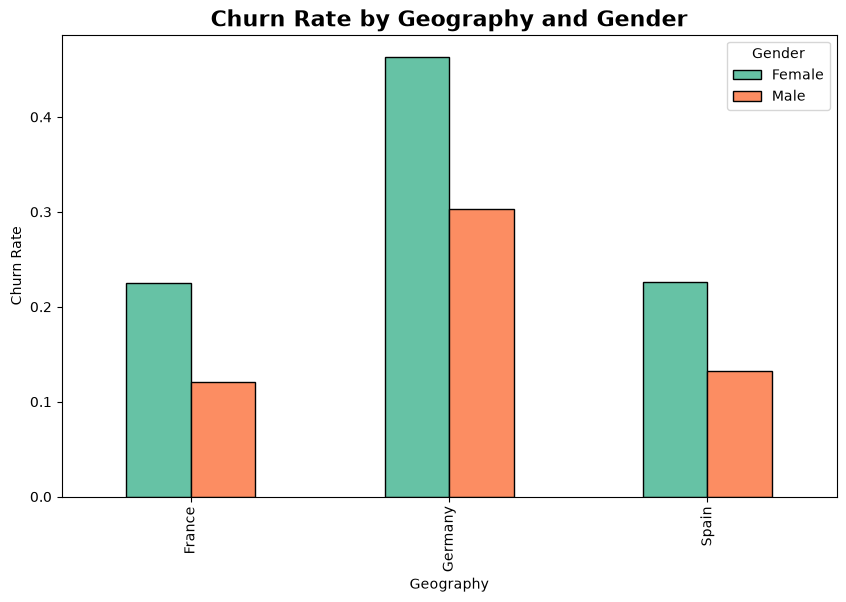

In [149]:
df.groupby(["Geography", "Gender"])["Exited"].mean().unstack().plot(kind="bar", figsize=(10, 6), edgecolor="black")
plt.title("Churn Rate by Geography and Gender", fontsize=16, fontweight="bold")
plt.xlabel("Geography")
plt.ylabel("Churn Rate")
plt.legend(title="Gender")
plt.show()

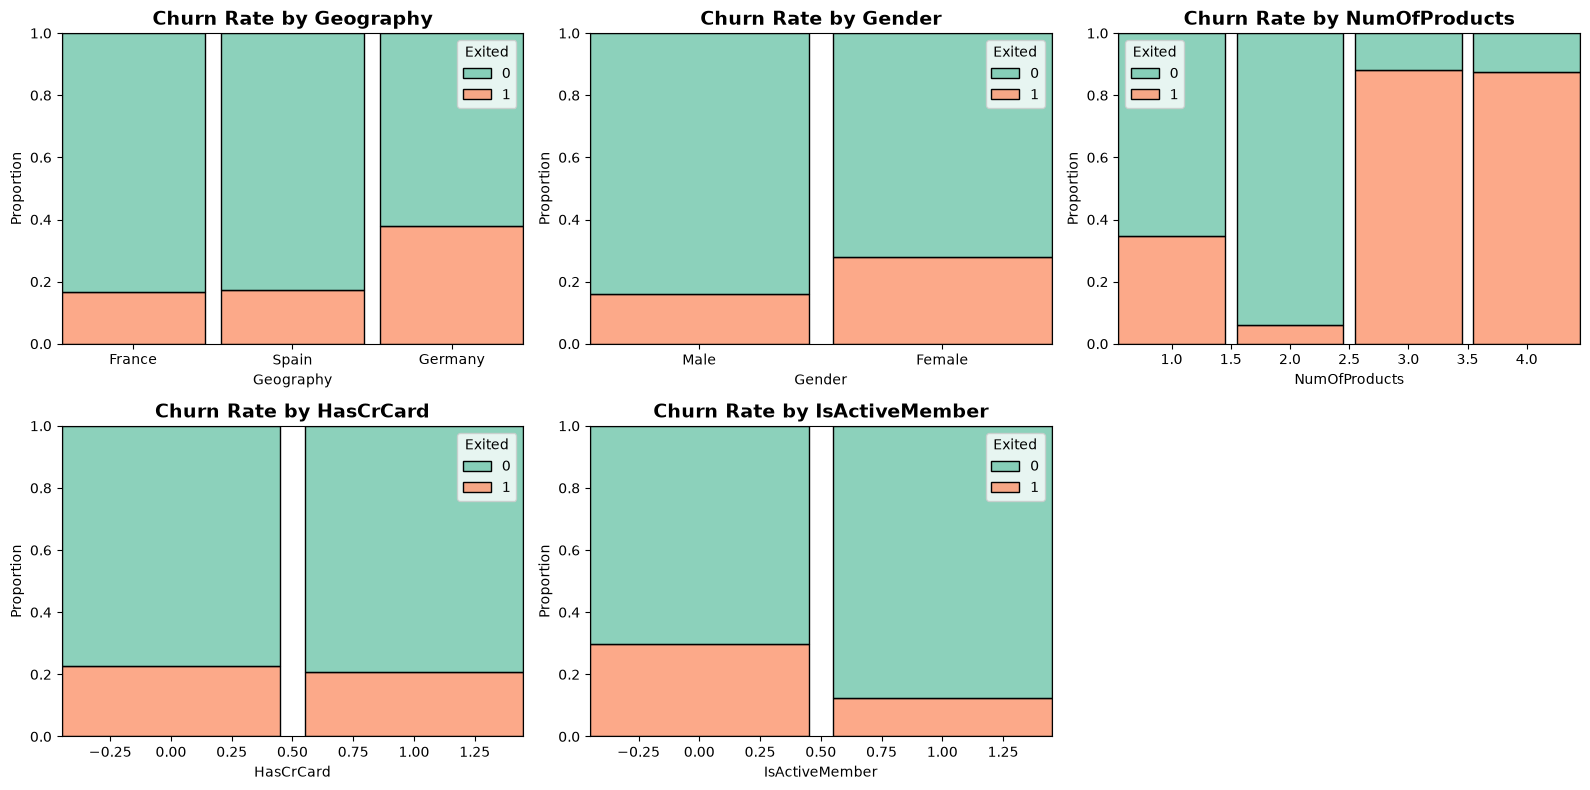

In [150]:
plt.figure(figsize=(16, 8))
for i, c in enumerate(["Geography", "Gender", "NumOfProducts", "HasCrCard", "IsActiveMember"]):
    plt.subplot(2, 3, i + 1)
    # Changed to histplot, added hue="Exited", and fixed shrink (no 's')
    ax = sns.histplot(x=c, hue="Exited", data=df, multiple="fill", discrete=True, shrink=.9, palette="Set2", edgecolor="black")
    
    # Optional: Note that ax.bar_label might need adjustment depending on how bins are generated
    ax.set_ylabel("Proportion")
    ax.set_title(f"Churn Rate by {c}", fontsize=14, fontweight="bold")
plt.tight_layout()


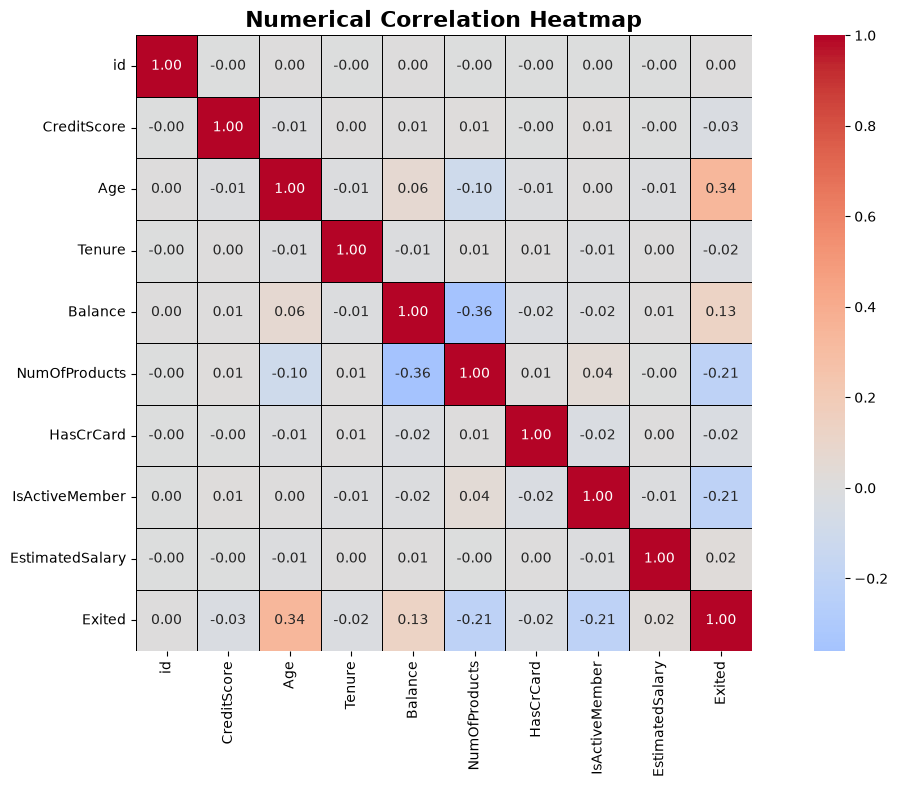

In [151]:
plt.figure(figsize=(16, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5, linecolor="black", square=True)
plt.title("Numerical Correlation Heatmap", fontsize=16, fontweight="bold")
plt.show()

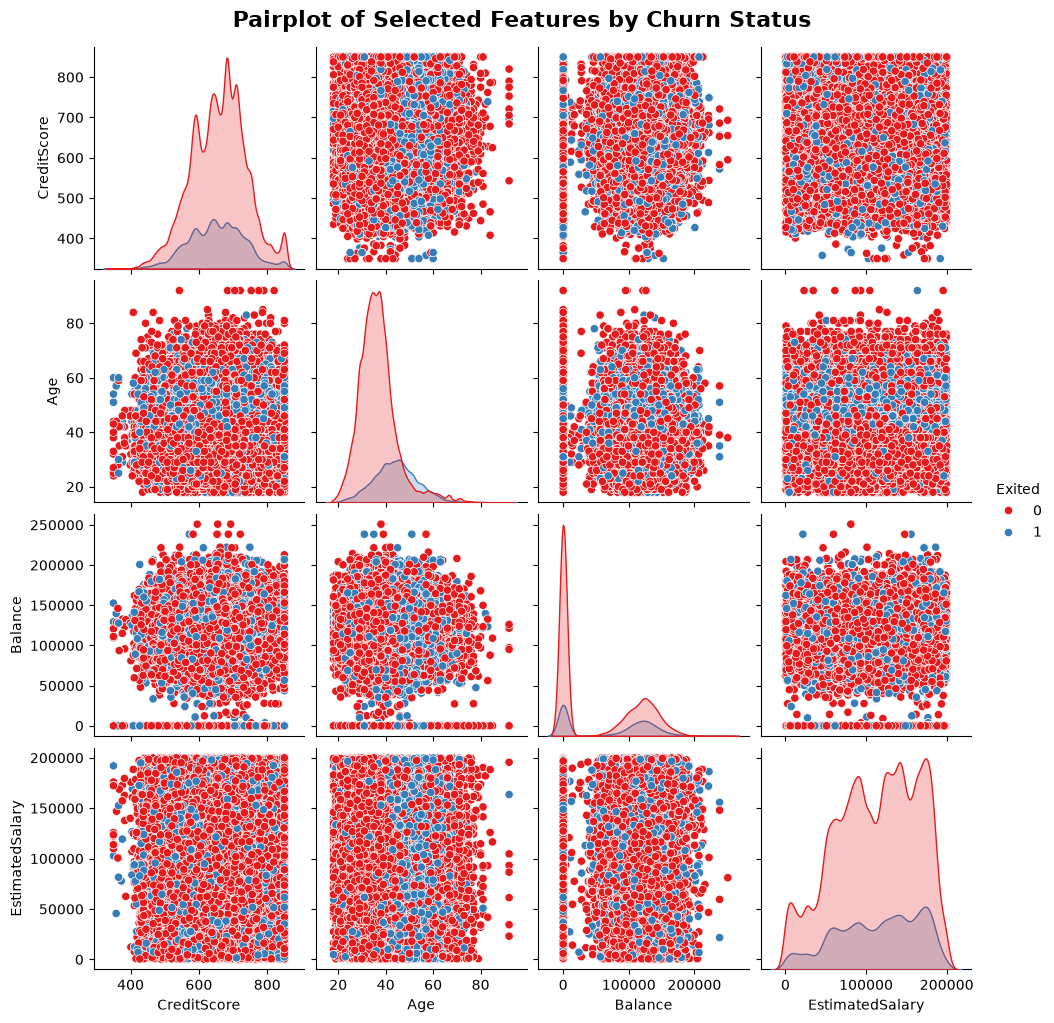

In [152]:
sns.pairplot(df, hue="Exited", vars=["CreditScore", "Age", "Balance", "EstimatedSalary"], palette="Set1")
plt.suptitle("Pairplot of Selected Features by Churn Status", fontsize=16, fontweight="bold", y=1.02)  # Adjust y for spacing
plt.show()

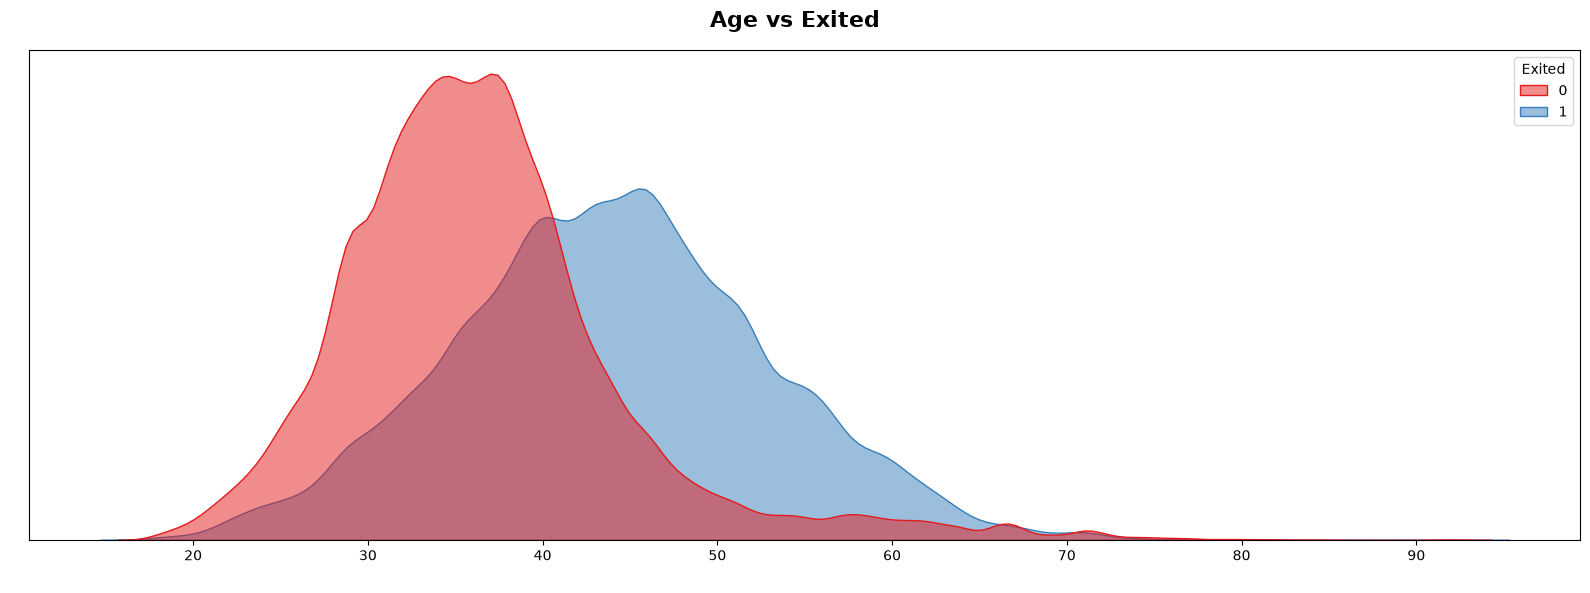

In [153]:
sns.set_palette("Set1", 3) 
fig = plt.figure(figsize=(16, 6))
g = sns.kdeplot(data=df, x="Age", hue="Exited", fill=True, common_norm=False, alpha=0.5, palette="Set1", label="Exited")
g.set_xlabel(" "); g.set_ylabel(" "); plt.yticks([])

fig.suptitle(f"Age vs Exited", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

In [154]:
from category_encoders import TargetEncoder
t_encoder = TargetEncoder()
df["SurnameExitedRate"]= t_encoder.fit_transform(df["Surname"], df["Exited"])
df["SurnameExitedRate"]

0         0.318008
1         0.326667
2         0.222052
3         0.181991
4         0.146341
            ...   
165029    0.245774
165030    0.217252
165031    0.209283
165032    0.229757
165033    0.256887
Name: SurnameExitedRate, Length: 165034, dtype: float64

<Figure size 1600x800 with 0 Axes>

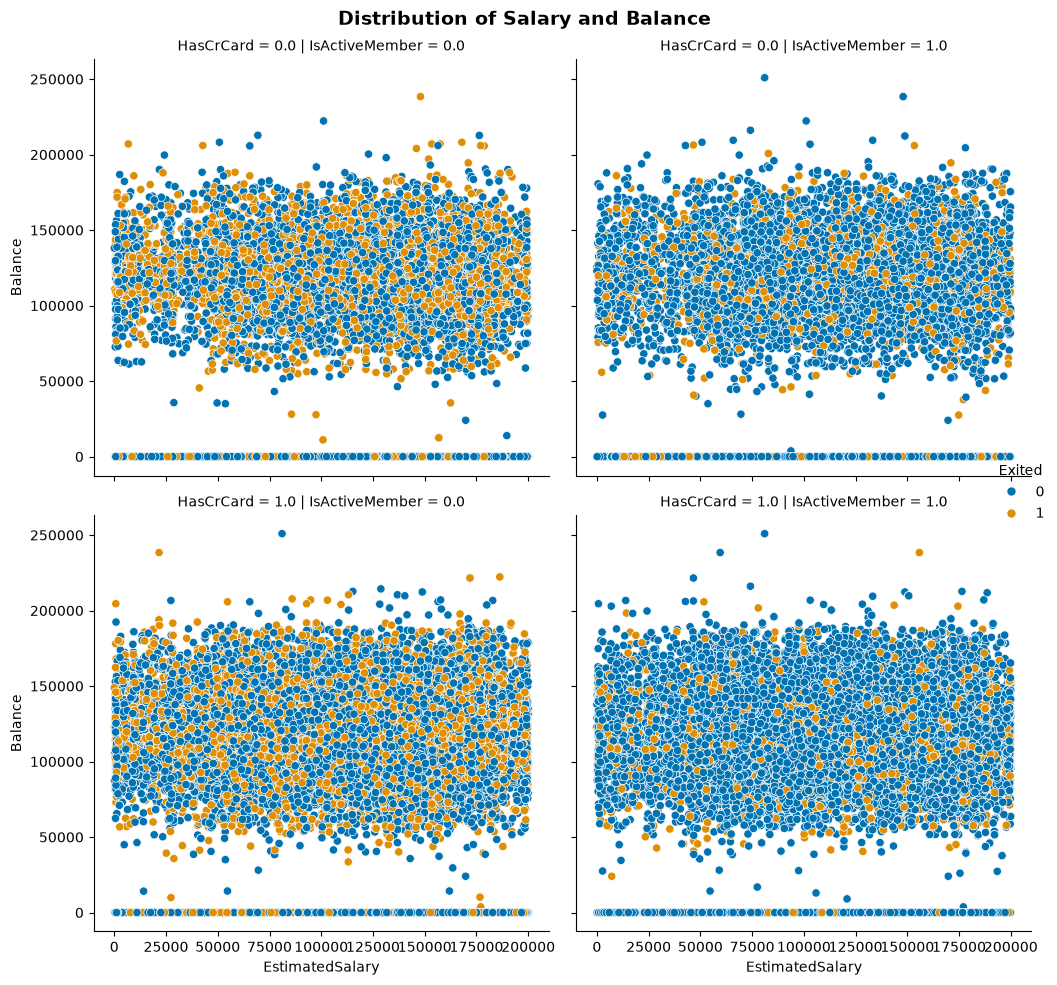

In [155]:
plt.figure(figsize=(16, 8))
sns.relplot(data=df, x="EstimatedSalary", y="Balance", hue="Exited", col="IsActiveMember", row="HasCrCard", kind="scatter", palette=sns.color_palette("colorblind", 2))
plt.suptitle("Distribution of Salary and Balance", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

In [156]:
df.groupby(["HasCrCard", "IsActiveMember"])["Exited"].mean()

HasCrCard  IsActiveMember
0.0        0.0               0.309427
           1.0               0.150573
1.0        0.0               0.293253
           1.0               0.116704
Name: Exited, dtype: float64

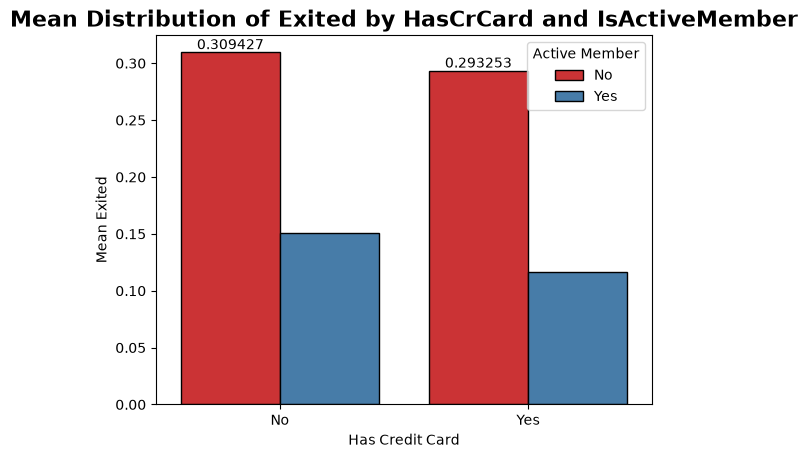

In [157]:
g = sns.barplot(x="HasCrCard", y="Exited", hue="IsActiveMember", data=df, ci=None, edgecolor="black")
g.bar_label(g.containers[0])
plt.title("Mean Distribution of Exited by HasCrCard and IsActiveMember", fontsize=16, fontweight="bold")
plt.xlabel("Has Credit Card")
plt.ylabel("Mean Exited")
plt.xticks([0,1], ["No", "Yes"])
plt.legend(title="Active Member", loc="upper right", labels=["No", "Yes"])
plt.show()

In [158]:
df["ActiveCrCard"] = df["HasCrCard"] + df["IsActiveMember"]
df["ActiveCrCard"]

0         1.0
1         2.0
2         1.0
3         2.0
4         2.0
         ... 
165029    2.0
165030    0.0
165031    2.0
165032    1.0
165033    1.0
Name: ActiveCrCard, Length: 165034, dtype: float64

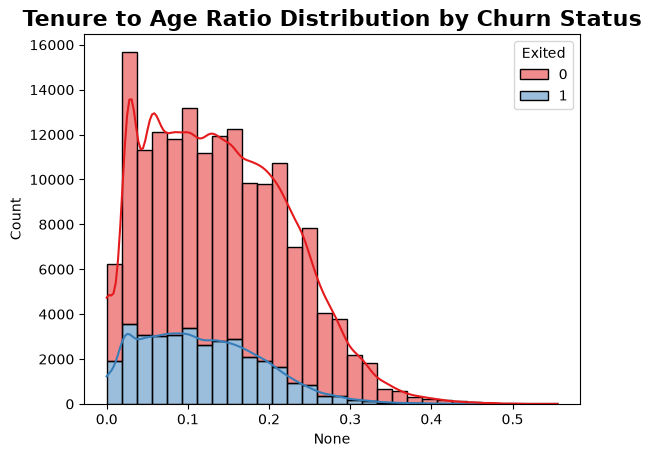

In [159]:
sns.histplot(x=df["Tenure"]/df["Age"], data=df, bins=30, kde=True, color="purple", edgecolor="black", hue="Exited", multiple="stack", palette="Set1")
plt.title("Tenure to Age Ratio Distribution by Churn Status", fontsize=16, fontweight="bold")
plt.show()

In [160]:
df["Tenure_to_Age_Ratio"] = df["Tenure"] / df["Age"]
df["Tenure_to_Age_Ratio"]

0         0.090909
1         0.030303
2         0.250000
3         0.058824
4         0.151515
            ...   
165029    0.060606
165030    0.085714
165031    0.161290
165032    0.233333
165033    0.032258
Name: Tenure_to_Age_Ratio, Length: 165034, dtype: float64

In [161]:
df.groupby("Tenure")["Exited"].mean()

Tenure
0     0.254843
1     0.226134
2     0.194846
3     0.229104
4     0.226387
5     0.220060
6     0.198774
7     0.187591
8     0.197945
9     0.212101
10    0.212726
Name: Exited, dtype: float64

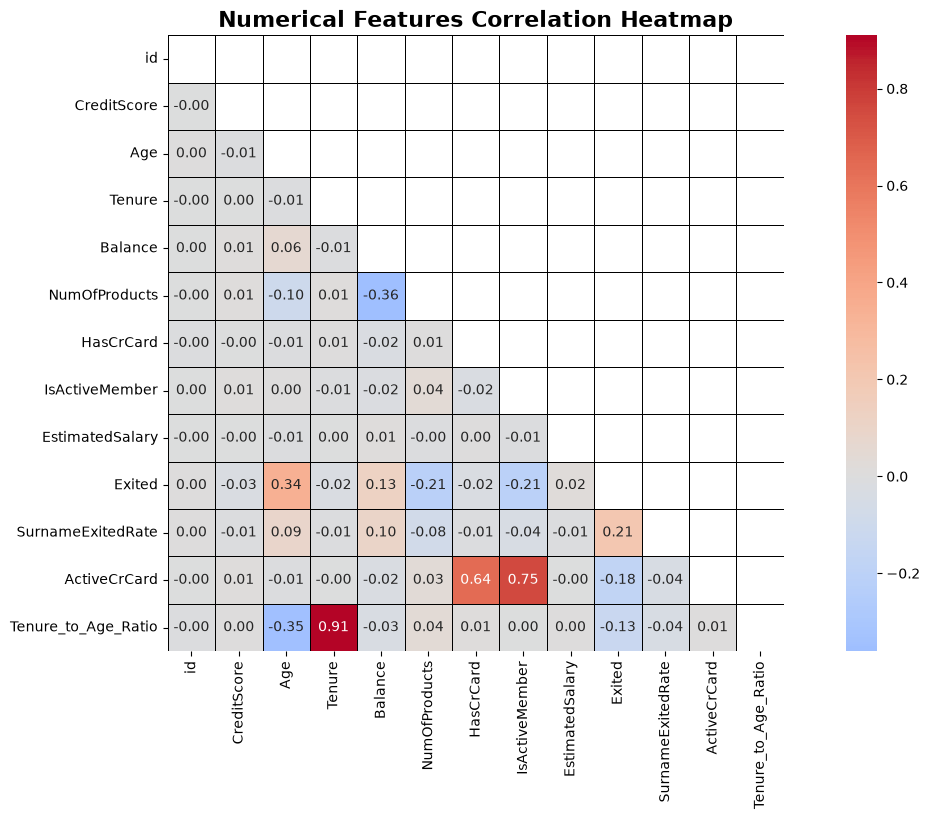

In [162]:
plt.figure(figsize=(16, 8))
sns.heatmap(df.corr(numeric_only=True), mask=np.triu(df.select_dtypes(exclude="object").corr()), annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5, linecolor="black", square=True)
plt.title("Numerical Features Correlation Heatmap", fontsize=16, fontweight="bold")
plt.show()

## 📊 Project Overview: Bank Customer Churn Analysis
Based on the exploratory data analysis (EDA) of the bank customer dataset, this project focuses on predicting customer churn (whether a customer will close their account or stay) and identifying key behavioral and demographic indicators of attrition.
## 🔍 Key Insights & Findings

* Churn Baseline: Only 21% of customers in the dataset have churned, indicating a class imbalance.
* Demographics:
* The majority of customers are from France. However, Germany exhibits the highest churn rate.
   * The dataset is predominantly male, yet female customers show a higher churn rate.
* Customer Behavior:
* Activity Status: A high percentage of members are inactive. Non-active status is a significant indicator of churn.
   * Product Usage: Customers holding 3 or 4 products show noticeably higher churn rates.
   * Account Balance: A large number of customers have zero balances, likely using the bank for non-saving operations.
* Correlations: Weak linear correlations exist between churn and features like age, active membership, balance, and number of products. Churned age distributions appear normal.

------------------------------
## 🛠️ Feature Engineering & Data Prep
To optimize machine learning performance, the following preprocessing steps and feature additions are proposed:
## Encoding Strategies

* Target Encoding: To be applied to the Surname column (which contains non-unique row identifiers and high cardinality).
* One-Hot Encoding: To be applied to the Geography feature due to low cardinality (mostly France, Germany, Spain).

## New Engineered Features

* Age-to-Tenure Ratio: Captures customer loyalty relative to their life stage.
* Surname Exited Rate: Leverages historical churn patterns within family names/clusters.
* Active Credit Card Status: Combines credit card ownership with overall account activity.

## Feature Selection

* Multicollinearity: To improve model interpretability, removing IsActiveMember, HasCrCard, and Tenure is suggested after creating engineered features, though advanced ML algorithms can naturally handle these if retained.

------------------------------
## 🚀 Next Steps

   1. Implement the proposed feature engineering pipeline.
   2. Balance the dataset using resampling techniques (e.g., SMOTE) if necessary.
   3. Train and evaluate predictive classification models (e.g., XGBoost, Random Forest).
   4. Deploy targeted customer retention strategies based on model risk scores.





In [163]:
X = df.drop(columns=["Exited", "id"])
y = df["Exited"]

#  Splitting the Dataset

In [164]:
X_train, xtemp, y_train, ytemp = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_valid, X_test, y_valid, y_test = train_test_split(xtemp, ytemp, test_size=0.5, random_state=42, stratify=ytemp)

In [165]:
print("Training shape:", X_train.shape, y_train.shape)
print("Validation shape:", X_valid.shape, y_valid.shape)
print("Test shape:", X_test.shape, y_test.shape)

print("\n\n")
print("\nTraining set class distribution:\n", y_train.value_counts(normalize=True))
print("\nValidation set class distribution:\n", y_valid.value_counts(normalize=True))
print("\nTest set class distribution:\n", y_test.value_counts(normalize=True))

Training shape: (132027, 14) (132027,)
Validation shape: (16503, 14) (16503,)
Test shape: (16504, 14) (16504,)




Training set class distribution:
 Exited
0    0.788399
1    0.211601
Name: proportion, dtype: float64

Validation set class distribution:
 Exited
0    0.788402
1    0.211598
Name: proportion, dtype: float64

Test set class distribution:
 Exited
0    0.788415
1    0.211585
Name: proportion, dtype: float64


#  Feature Scaling

In [166]:
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, TargetEncoder, FunctionTransformer

# 1. Base building-block pipelines
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False, drop="first"))
])

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

target_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encode", TargetEncoder())
])

# 2. Custom feature engineering functions
def ActiveCrdCard_function(X):
    # Explicitly copy to avoid SettingWithCopyWarning
    X_out = X.copy()
    X_out["ActiveCrCard"] = X_out["HasCrCard"] + 4 * X_out["IsActiveMember"]
    return X_out[["ActiveCrCard"]]

def Tenure_to_Age_Ratio_function(X):
    X_out = X.copy()
    X_out["Tenure_to_Age_Ratio"] = X_out["Tenure"] / X_out["Age"]
    return X_out[["Tenure_to_Age_Ratio"]]

# 3. Feature engineering pipelines (Engineering FIRST, then Impute/Scale)
ActiveCrCard_transformer_pipeline = make_pipeline(
    FunctionTransformer(ActiveCrdCard_function, validate=False),
    SimpleImputer(strategy="median") # Impute engineered feature if needed
)

Tenure_to_Age_Ratio_transformer_pipeline = make_pipeline(
    FunctionTransformer(Tenure_to_Age_Ratio_function, validate=False),
    SimpleImputer(strategy="median")
)

# 4. Global Column Transformer
preprocession_pipeline = ColumnTransformer([
    ("N", num_pipeline, ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "EstimatedSalary"]),
    ("ActiveCrCard", ActiveCrCard_transformer_pipeline, ["HasCrCard", "IsActiveMember"]),
    ("Tenure_to_Age_Ratio", Tenure_to_Age_Ratio_transformer_pipeline, ["Tenure", "Age"]),
    ("Age", num_pipeline, ["Age"]), # Directly pass to num_pipeline, no lambda needed
    ("Cat", cat_pipeline, ["Geography", "Gender"]), # Directly pass to cat_pipeline, no lambda needed
    ("Tar", target_pipeline, ["Surname", "NumOfProducts", "Gender", "Geography", "Tenure"]), # Fixed reference name
], remainder="drop", verbose_feature_names_out=False)

# 5. Final Meta-Pipeline
preprocession = Pipeline([
    ("preprocession", preprocession_pipeline),
    ("scaler", StandardScaler()) # Final scale across all engineered columns
])
preprocession

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocession', ...), ('scaler', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('N', ...), ('ActiveCrCard', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``"

In [167]:
import pandas as pd

train_preprocessed = pd.DataFrame(preprocession.fit_transform(X_train, y_train)).replace(0, -1)
valid_preprocessed = pd.DataFrame(preprocession.transform(X_valid)).replace(0, -1)
test_preprocessed = pd.DataFrame(preprocession.transform(X_test)).replace(0, -1)

In [168]:
train_preprocessed.sample()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
84575,0.31849,0.325084,-0.362666,0.503911,0.815324,-0.38761,-1.347258,-0.481537,0.325084,-0.514619,1.88057,0.878951,0.207241,-0.884015,-0.893048,-0.480193,0.730934


## Building Random Forest Classifier

In [169]:
rfmodel = RandomForestClassifier(random_state=42, n_estimators=100, max_depth=None, min_samples_split=2, min_samples_leaf=1, max_features="sqrt", bootstrap=True)
rfmodel.fit(train_preprocessed, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [170]:
def evaluate_model(model):
    train_preds = model.predict(train_preprocessed)
    valid_preds = model.predict(valid_preprocessed)
    print("Training Accuracy:", accuracy_score(y_train, train_preds))
    print("Validation Accuracy:", accuracy_score(y_valid, valid_preds))
    test_preds = model.predict(test_preprocessed)
    print("Test Accuracy:", accuracy_score(y_test, test_preds))
    
    print("\n")
    ts_preds =model.predict_proba(valid_preprocessed)[:, 1]
    tr_preds = model.predict_proba(train_preprocessed)[:, 1]
    print("Validation ROC AUC:", roc_auc_score(y_valid, ts_preds))
    print("Training ROC AUC:", roc_auc_score(y_train, tr_preds))
    
    
evaluate_model(rfmodel)
    

Training Accuracy: 0.999931832125247
Validation Accuracy: 0.8657213839907896
Test Accuracy: 0.8591250605913718


Validation ROC AUC: 0.8876417504863935
Training ROC AUC: 0.9999999773036949


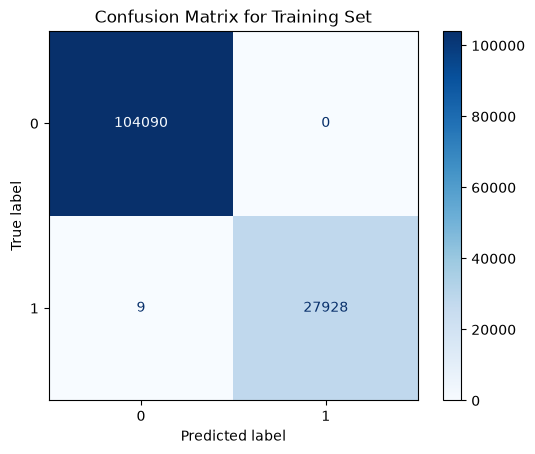

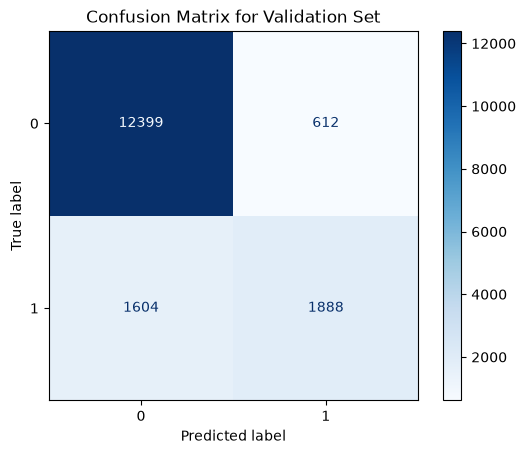

In [171]:
def plot_confusion_matrix(model, X, y, dataset_name):
    preds = model.predict(X)
    cm = confusion_matrix(y, preds)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"Confusion Matrix for {dataset_name} Set")
    plt.show()
    
plot_confusion_matrix(rfmodel, train_preprocessed, y_train, "Training")
plot_confusion_matrix(rfmodel, valid_preprocessed, y_valid, "Validation")

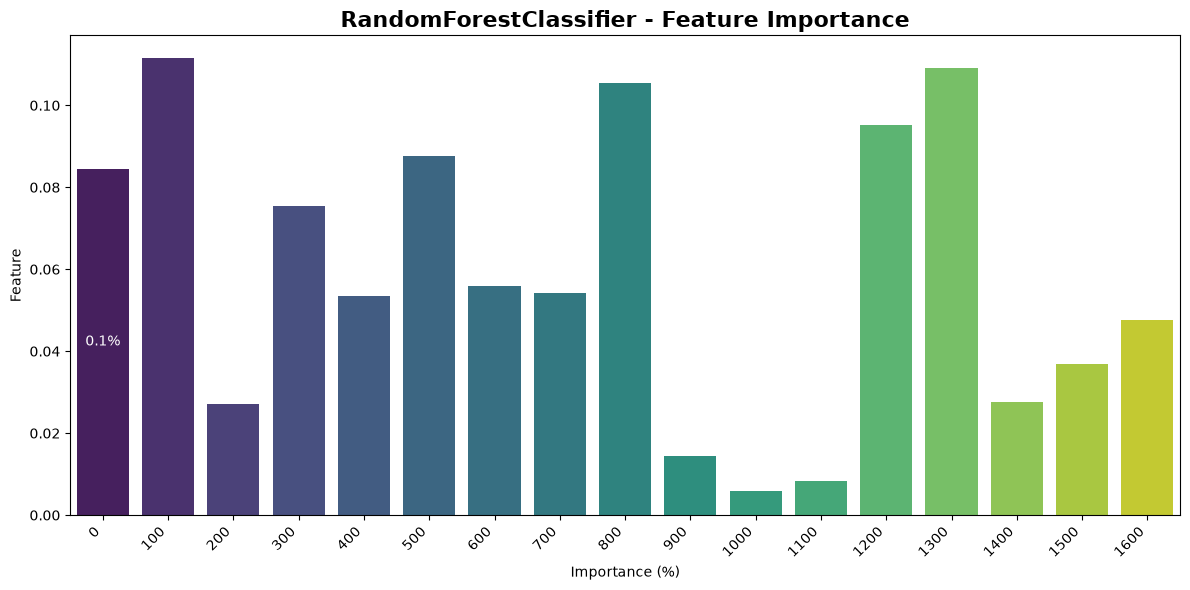

In [172]:
def plot_feature_importance(model):
    feature_importances = model.feature_importances_
    model_name = type(model).__name__
    feature_importances_df = pd.DataFrame({
        "Feature": train_preprocessed.columns,
        "Importance": feature_importances
    }).sort_values(by="Importance", ascending=False)
    
    plt.figure(figsize=(12, 6))
    a = sns.barplot(y=feature_importances_df["Importance"][:18], x=feature_importances_df["Feature"][:18]*100, palette="viridis")
    heights =[str(round(height,1))+"%" for height in  a.containers[0].datavalues]
    a.bar_label(a.containers[0], labels=heights, label_type="center", fontsize=10, color="white")
    plt.title(f"{model_name} - Feature Importance", fontsize=16, fontweight="bold")
    plt.xlabel("Importance (%)")
    plt.ylabel("Feature")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
plot_feature_importance(rfmodel)

In [173]:
tt_predict = rfmodel.predict_proba(test_preprocessed)[:, 1]
print("Test AUC:", roc_auc_score(y_test, tt_predict))  


Test AUC: 0.8810615692132279


In [174]:

xgmodel = XGBClassifier(
    random_state=42, 
    n_estimators=100, 
    max_depth=6, 
    learning_rate=0.1, 
    subsample=0.8, 
    colsample_bytree=0.8, 
    n_jobs=-1
)

xgmodel.set_params(
    early_stopping_rounds=10,
    eval_metric="auc"
)
xgmodel.fit(
    train_preprocessed, 
    y_train, 
    eval_set=[(valid_preprocessed, y_valid)], 
    verbose=False
)


,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",10
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'auc'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [175]:
evaluate_model(xgmodel)

Training Accuracy: 0.8734728502503276
Validation Accuracy: 0.8695994667636188
Test Accuracy: 0.8649418322830829


Validation ROC AUC: 0.8968402848484097
Training ROC AUC: 0.9035719145646567


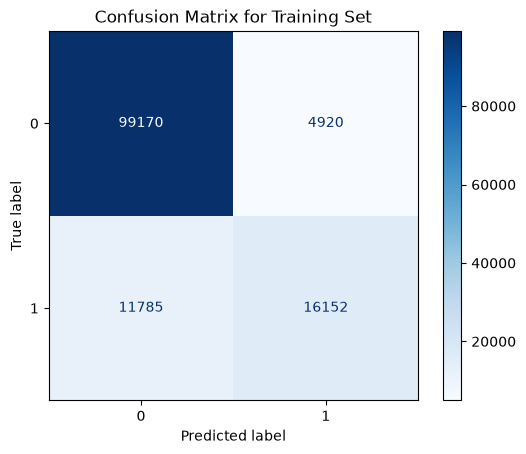

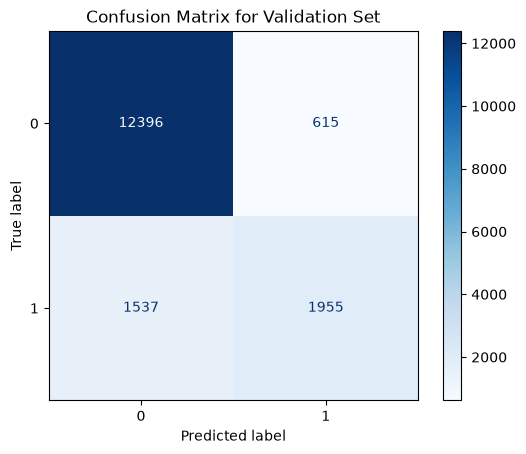

In [176]:
plot_confusion_matrix(xgmodel, train_preprocessed, y_train, "Training")
plot_confusion_matrix(xgmodel, valid_preprocessed, y_valid, "Validation")

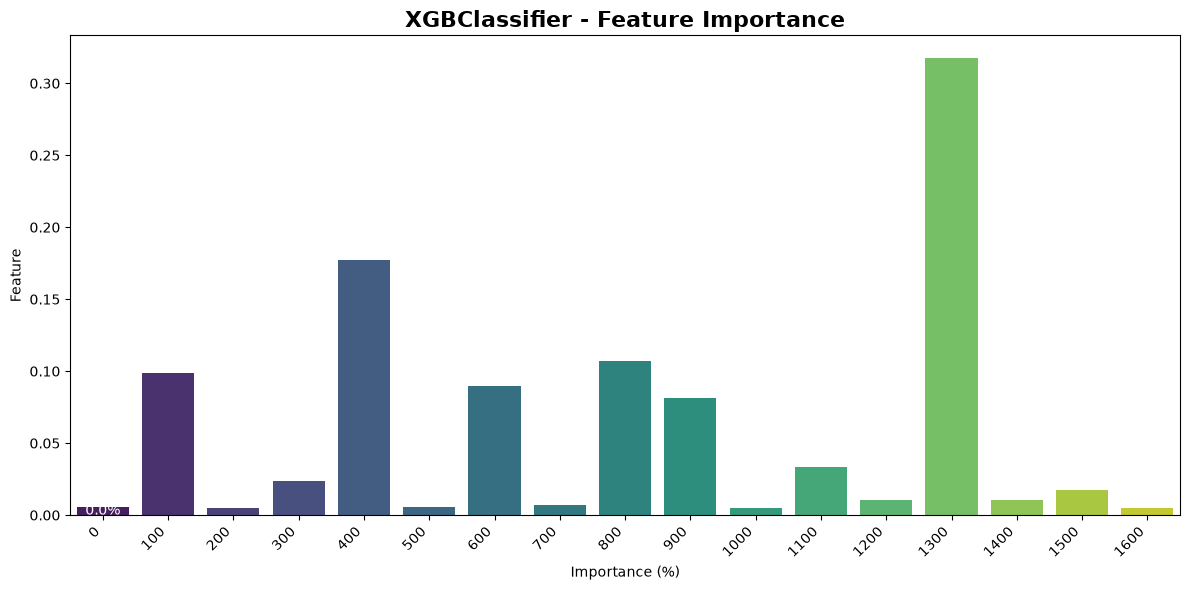

In [177]:
plot_feature_importance(xgmodel)

In [178]:
lgbm_model = LGBMClassifier(
    random_state=42,
    n_estimators=100,
    max_depth=-1,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    n_jobs=-1
)
lgbm_model.fit(train_preprocessed, y_train)

[LightGBM] [Info] Number of positive: 27937, number of negative: 104090
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.009034 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1547
[LightGBM] [Info] Number of data points in the train set: 132027, number of used features: 17
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.211601 -> initscore=-1.315304
[LightGBM] [Info] Start training from score -1.315304


,subsample,0.8
,colsample_bytree,0.8
,random_state,42
,n_jobs,-1
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,objective,None


In [179]:
evaluate_model(lgbm_model)

Training Accuracy: 0.8725715194619282
Validation Accuracy: 0.8705083924135005
Test Accuracy: 0.8649418322830829


Validation ROC AUC: 0.8962613734277006
Training ROC AUC: 0.902900438191027


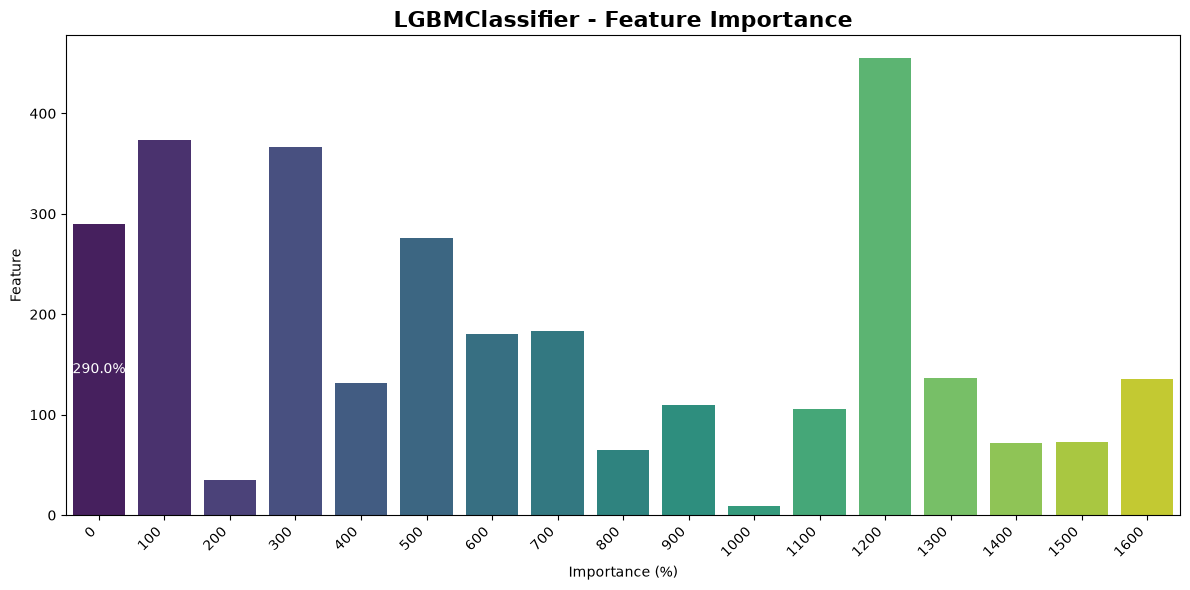

In [180]:
plot_feature_importance(lgbm_model)

In [181]:
param_grid = {
    "learning_rate": [0.01, 0.1, 0.2],
    "n_estimators":[40, 100, 200],
    "num_leaves": [20, 30, 40],
    "max_depth": [5, 10, 15]
}

lgmodel = LGBMClassifier(verbos=0)


grid_search = GridSearchCV(lgmodel, param_grid, cv=5, scoring="accuracy", verbose=1)
grid_search.fit(train_preprocessed, y_train)

print("Best Hyperparameter:", grid_search.best_params_)

best_model = grid_search.best_estimator_
best_model.fit(train_preprocessed, y_train)

Fitting 5 folds for each of 81 candidates, totalling 405 fits
[LightGBM] [Warning] Unknown parameter: verbos
[LightGBM] [Warning] Unknown parameter: verbos
[LightGBM] [Info] Number of positive: 22349, number of negative: 83272
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.014208 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1545
[LightGBM] [Info] Number of data points in the train set: 105621, number of used features: 17
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.211596 -> initscore=-1.315331
[LightGBM] [Info] Start training from score -1.315331
[LightGBM] [Warning] Unknown parameter: verbos
[LightGBM] [Warning] Unknown parameter: verbos
[LightGBM] [Warning] Unknown parameter: verbos
[LightGBM] [Info] Number of positive: 22349, number of negative: 83272
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of

,num_leaves,20
,max_depth,15
,n_estimators,200
,verbos,0
,boosting_type,'gbdt'
,learning_rate,0.1
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001


In [182]:
print("Best Hyperparameters: ", grid_search.best_params_)

Best Hyperparameters:  {'learning_rate': 0.1, 'max_depth': 15, 'n_estimators': 200, 'num_leaves': 20}


In [183]:
best_model = LGBMClassifier(**grid_search.best_params_)
best_model.fit(train_preprocessed, y_train)

[LightGBM] [Info] Number of positive: 27937, number of negative: 104090
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.038258 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1547
[LightGBM] [Info] Number of data points in the train set: 132027, number of used features: 17
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.211601 -> initscore=-1.315304
[LightGBM] [Info] Start training from score -1.315304


,num_leaves,20
,max_depth,15
,n_estimators,200
,boosting_type,'gbdt'
,learning_rate,0.1
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


In [184]:
evaluate_model(best_model)

Training Accuracy: 0.8743211615805858
Validation Accuracy: 0.8698418469369206
Test Accuracy: 0.864032961706253


Validation ROC AUC: 0.8966995104943805
Training ROC AUC: 0.9062435040209066


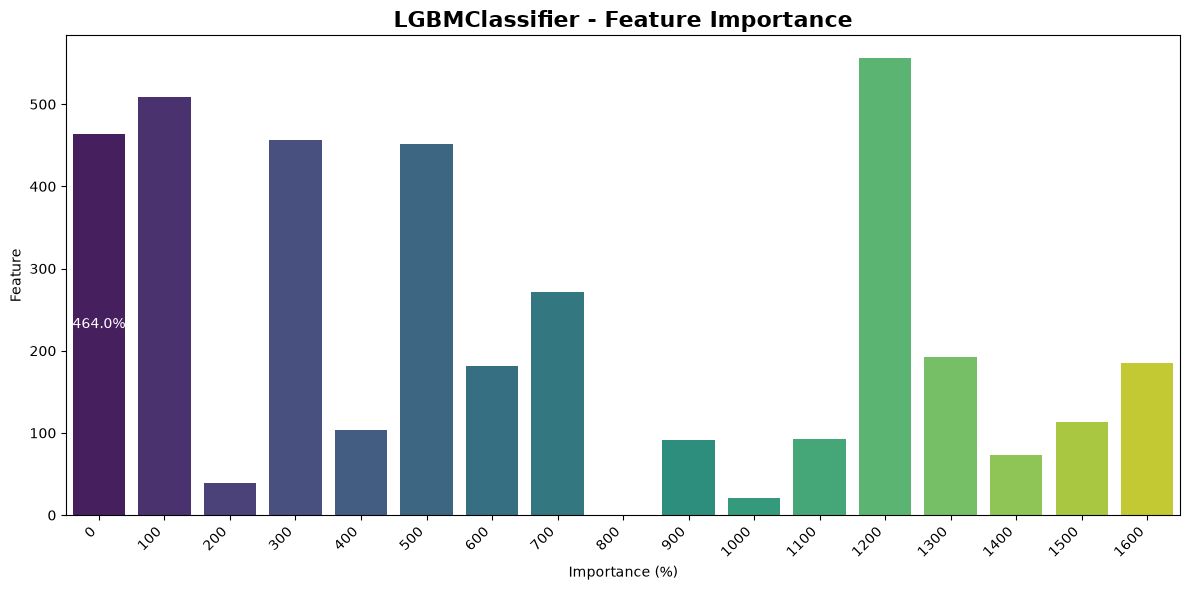

In [185]:
plot_feature_importance(best_model)

In [186]:
cat_model = CatBoostClassifier(
    eval_metric="AUC",
    learning_rate=0.0009,
    iterations=9000,
    random_seed=42
)

cat_model.fit(train_preprocessed, y_train, eval_set=(valid_preprocessed, y_valid), verbose=1000)

0:	test: 0.8615464	best: 0.8615464 (0)	total: 295ms	remaining: 44m 14s
1000:	test: 0.8866464	best: 0.8866464 (1000)	total: 33.2s	remaining: 4m 25s
2000:	test: 0.8912368	best: 0.8912368 (2000)	total: 1m	remaining: 3m 33s
3000:	test: 0.8934287	best: 0.8934287 (3000)	total: 1m 29s	remaining: 2m 58s
4000:	test: 0.8944837	best: 0.8944837 (4000)	total: 2m 10s	remaining: 2m 43s
5000:	test: 0.8950711	best: 0.8950711 (5000)	total: 3m 54s	remaining: 3m 7s
6000:	test: 0.8954790	best: 0.8954790 (6000)	total: 5m 18s	remaining: 2m 39s
7000:	test: 0.8958092	best: 0.8958092 (7000)	total: 6m 27s	remaining: 1m 50s
8000:	test: 0.8960712	best: 0.8960712 (8000)	total: 6m 49s	remaining: 51.1s
8999:	test: 0.8962860	best: 0.8962860 (8999)	total: 7m 8s	remaining: 0us

bestTest = 0.8962859693
bestIteration = 8999



CatBoostClassifier(eval_metric='AUC', iterations=9000, learning_rate=0.0009, random_seed=42)

In [187]:
evaluate_model(cat_model)

Training Accuracy: 0.8684587243518371
Validation Accuracy: 0.8702660122401987
Test Accuracy: 0.8640935530780417


Validation ROC AUC: 0.8962859693221077
Training ROC AUC: 0.8944936473781626


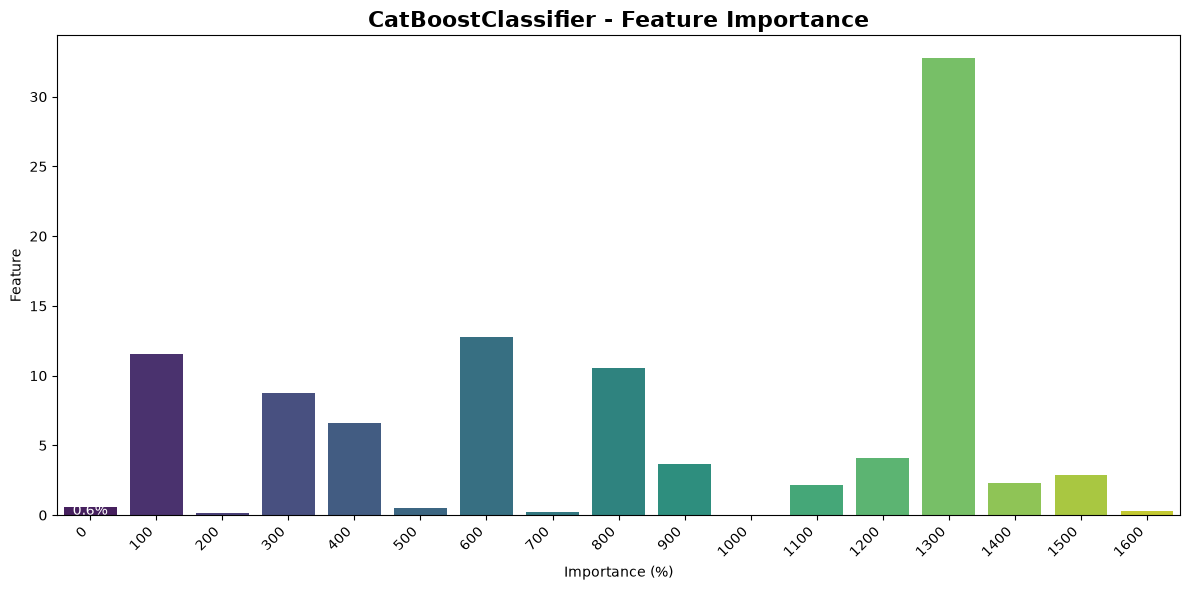

In [188]:
plot_feature_importance(cat_model)

In [189]:
tt_preds = cat_model.predict_proba(test_preprocessed)[:,1]
print("Test AUC Score:", roc_auc_score(y_test, tt_preds))

Test AUC Score: 0.8900542155289557


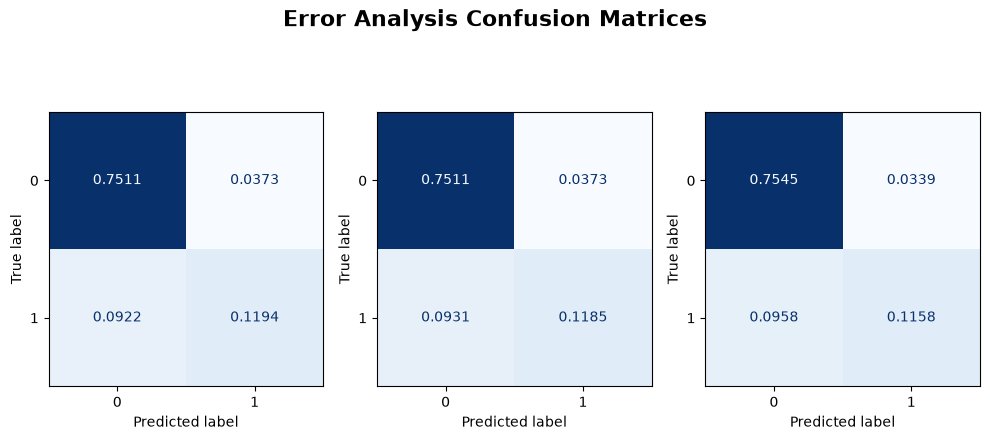

In [190]:
def error_analysis(models):
    fig, ax = plt.subplots(1, 3, figsize=(10, 5))
    
    for model in models: 
        yv_pred = model.predict(valid_preprocessed)
        m = confusion_matrix(y_valid, yv_pred, normalize="all")
        disp = ConfusionMatrixDisplay(confusion_matrix=m, display_labels=model.classes_)
        disp.plot(ax=ax[models.index(model)], cmap=plt.cm.Blues, values_format=".4f", colorbar=False)
    plt.tight_layout()
    fig.suptitle("Error Analysis Confusion Matrices", fontsize=16, fontweight="bold")
    plt.show()
error_analysis([lgbm_model, xgmodel, cat_model])